## **Project Notebook - Marketing Analytics**  
## *Marketing Mix Modelling with Meridian and SHAP Explainability*  

---

**Author:** *Matteo Fumagalli*  
**Student ID:** *894468*  
**University:** *University of Milano-Bicocca*  
**Degree Program:** *Master’s Degree in Data Science*   
**Academic Year:** *2025/2026*

---

### **Notebook Description**
This notebook implements a Marketing Mix Modelling pipeline using Google Meridian to quantify the contribution of each marketing channel, estimate channel-level ROI and marginal ROI, estimate future investment scenarios, and explain model predictions using SHAP.

All steps are fully reproducible from the files provided in the project repository.

---

## **0 - Environment Setup and Dataset Inspection**

In [3]:
# Import libraries
import pandas as pd

# Define the main folder path
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))

# Local imports (eda)
from src.eda import (
    load_organisation_dataset,
    inspect_missing_values, impute_missing_values,
    analyse_spending_channels,
    plot_purchases, plot_media_spend, plot_correlation,
    inspect_outliers
)

# Local imports (preprocessing)
from src.preprocessing import preprocess_dataset

# Local imports (modeling)
from src.modeling import (
    load_mmm_dataset, define_input_data, train_mmm_model,
    load_model, inspect_model_convergence, plot_model_quality,
    plot_adstock_effects, plot_hill_effects,
    plot_channel_contribution
)

# Local imports (roi)
from src.roi import (
    create_analyzer,
    compute_incremental_contribution,
    compute_roi, compute_mroi, compute_roi_probability,
    plot_response_curves
)

# Local imports (shap analysis)
from src.shap_analysis import (
    build_train_test_sets, train_ml_model, evaluate_ml_model,
    compute_shap_values,
    plot_summary, plot_dependence,
    plot_feature_importance,
    compare_shap_importance_with_mmm_contribution
)

# Local imports (scenarios)
from src.scenarios import (
    compute_current_spend_levels, extract_channel_metrics, 
    get_most_performing_channel, get_saturated_channels, 
    optimize_scenario_1, optimize_scenario_2, 
    optimize_scenario_3, optimize_scenario_4,
    compare_scenarios
)

In [9]:
def load_dataset(path: str) -> pd.DataFrame:
    '''Load the dataset'''
    df = pd.read_csv(path)
    df['DATE_DAY'] = pd.to_datetime(df['DATE_DAY'])
    return df


def analyse_dataset(df: pd.DataFrame) -> None:
    '''Inspect the general characteristics of the dataset'''
    sectors = sorted(df['ORGANISATION_VERTICAL'].dropna().unique().tolist())
    territories = sorted(
        df['TERRITORY_NAME'][df['TERRITORY_NAME'] != 'All Territories'].unique())

    print('== DATASET SUMMARY ==')
    print(f"Unique Organisations: {df['ORGANISATION_ID'].nunique()}")
    print(f"Vertical Sectors: {', '.join(sectors)}")
    print(f"Time Interval: {df['DATE_DAY'].min().strftime('%Y-%m-%d')} -> "
          f"{df['DATE_DAY'].max().strftime('%Y-%m-%d')}")
    print(f"Territories: {', '.join(territories)}")


def analyse_organisations(df: pd.DataFrame) -> pd.DataFrame:
    '''Inspect the characteristics of each organisation'''
    rows = []
    for organisation_id in df['ORGANISATION_ID'].unique():
        organisation_df = df[df['ORGANISATION_ID'] == organisation_id]

        # Keep only the global data series
        all_territories_df = organisation_df[
            organisation_df['TERRITORY_NAME'] == 'All Territories'].copy()
        if all_territories_df.empty:
            continue

        # Extract useful metrics
        num_days = all_territories_df['DATE_DAY'].nunique()
        min_date = all_territories_df['DATE_DAY'].min()
        max_date = all_territories_df['DATE_DAY'].max()
        expected_days = (max_date - min_date).days + 1
        if num_days != expected_days:
            continue
        if all_territories_df['DATE_DAY'].duplicated().any():
            continue
        num_territories = organisation_df['TERRITORY_NAME'].nunique() - 1
        if num_territories == 0:
            continue

        # Evaluate coverage across channels
        spending_channels = [
            'GOOGLE_PAID_SEARCH_SPEND', 'GOOGLE_SHOPPING_SPEND',
            'GOOGLE_PMAX_SPEND', 'GOOGLE_DISPLAY_SPEND', 'GOOGLE_VIDEO_SPEND',
            'META_FACEBOOK_SPEND', 'META_INSTAGRAM_SPEND',
            'META_OTHER_SPEND', 'TIKTOK_SPEND']
        spending_channels_coverage = {}
        for channel in spending_channels:
            if channel in all_territories_df.columns:
                spending_channels_coverage[channel] = (
                    (all_territories_df[channel].notna()) &
                    (all_territories_df[channel] > 0)).mean()
        active_channels = [
            channel for channel, coverage in spending_channels_coverage.items()
                    if coverage >= 0.4]
        if not active_channels:
            continue
        num_active_channels = len(active_channels)

        # Obtain a summary DataFrame
        rows.append({
            'ORGANISATION_ID': organisation_id,
            'ORGANISATION_VERTICAL': 
                organisation_df['ORGANISATION_VERTICAL'].iloc[0],
            'PRIMARY_TERRITORY': 
                organisation_df['ORGANISATION_PRIMARY_TERRITORY_NAME'].iloc[0],
            'CURRENCY_CODE': organisation_df['CURRENCY_CODE'].iloc[0],
            'MIN_DATE': min_date.strftime('%Y-%m-%d'),
            'MAX_DATE': max_date.strftime('%Y-%m-%d'),
            'NUM_DAYS': num_days,
            'NUM_TERRITORIES': num_territories,
            'NUM_ACTIVE_CHANNELS': num_active_channels
        })

    if not rows:
        print('No organisation satifies minimal requirements')
        return pd.DataFrame()

    summary_df = pd.DataFrame(rows)
    summary_df = summary_df.sort_values(
        by=['NUM_ACTIVE_CHANNELS', 'NUM_TERRITORIES'],
        ascending=False).reset_index(drop=True)

    return summary_df

In [10]:
# Load the dataset and inspect column types
df = load_dataset('../data/conjura_mmm_data.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 132759 entries, 0 to 132758
Data columns (total 50 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   MMM_TIMESERIES_ID                    132759 non-null  str           
 1   ORGANISATION_ID                      132759 non-null  str           
 2   ORGANISATION_VERTICAL                124649 non-null  str           
 3   ORGANISATION_SUBVERTICAL             124649 non-null  str           
 4   ORGANISATION_MARKETING_SOURCES       132759 non-null  str           
 5   ORGANISATION_PRIMARY_TERRITORY_NAME  132759 non-null  str           
 6   TERRITORY_NAME                       132759 non-null  str           
 7   DATE_DAY                             132759 non-null  datetime64[us]
 8   CURRENCY_CODE                        132759 non-null  str           
 9   FIRST_PURCHASES                      132759 non-null  int64         
 10  FIRST_P

In [11]:
# Display main statistics of the dataset
analyse_dataset(df)

== DATASET SUMMARY ==
Unique Organisations: 93
Vertical Sectors: Apparel, Arts & Entertainment, Autos & Vehicles, Beauty & Fitness, Business & Industrial, Consumer Electronics, Food & Drink, Health, Home & Garden, Other, Pets & Animals, Safety & Survival, Sports, Toys & Hobbies, Travel
Time Interval: 2019-07-21 -> 2024-06-02
Territories: Australia, Austria, Canada, Denmark, France, Germany, Hong Kong, Ireland, Italy, Japan, Netherlands, New Zealand, Norway, Spain, Sweden, Switzerland, UK, US


In [12]:
# Analyse e-commerce brands for choosing the best one for subsequent steps
organisation_summary_df = analyse_organisations(df)
organisation_summary_df.head(5).style.format({'NUM_DAYS': '{:,.0f}'})

,ORGANISATION_ID,ORGANISATION_VERTICAL,PRIMARY_TERRITORY,CURRENCY_CODE,MIN_DATE,MAX_DATE,NUM_DAYS,NUM_TERRITORIES,NUM_ACTIVE_CHANNELS
0,7569a6a9c156a0f9398fa6cfd51df5bb,Food & Drink,US,USD,2021-10-15,2024-01-13,821,3,8
1,784d6aa3cda59f59f2400332b2420a49,Apparel,UK,GBP,2020-04-21,2024-03-05,"1,415",2,7
2,058b38dc1b5a87a8d9338196cd024d47,nan,UK,USD,2022-03-30,2023-06-30,458,2,6
3,4a762f02ca755b22d37393e8dbeab1a6,Apparel,US,USD,2021-07-26,2024-05-20,"1,030",2,6
4,f7e5ba45e3e337e8e90787ae0218a7ac,Home & Garden,UK,GBP,2021-06-08,2024-06-02,"1,091",2,5


---

## **1 - Exploratory Data Analysis**

In [3]:
# Load the dataset related to a single organisation
organisation_df = load_organisation_dataset(
    '../data/conjura_mmm_data.csv', '7569a6a9c156a0f9398fa6cfd51df5bb')

== DATASET LOADING ==
Dataset of organisation 7569a6a9c156a0f9398fa6cfd51df5bb correctly loaded


In [4]:
# Display a report for missing values
missing_values_df = inspect_missing_values(organisation_df)
missing_values_df

== MISSING VALUES ASSESSMENT ==


,COLUMN,NUM_MISSING,PERCENTAGE_MISSING
0,MMM_TIMESERIES_ID,0,0.00
1,ORGANISATION_ID,0,0.00
2,ORGANISATION_VERTICAL,0,0.00
3,ORGANISATION_SUBVERTICAL,0,0.00
4,ORGANISATION_MARKETING_SOURCES,0,0.00
5,ORGANISATION_PRIMARY_TERRITORY_NAME,0,0.00
6,TERRITORY_NAME,0,0.00
7,DATE_DAY,0,0.00
8,CURRENCY_CODE,0,0.00
9,FIRST_PURCHASES,0,0.00


In [5]:
# Impute missing values with 0 for media spend, clicks, and impressions
organisation_df = impute_missing_values(organisation_df)

== MISSING VALUES IMPUTATION ==
Imputation completed for NaN values in media spend, clicks, and impressions


In [8]:
# Analyse the coverage and spending of each media channel
media_channels_report_df = analyse_spending_channels(organisation_df)
media_channels_report_df.style.format({
    'TOTAL_SPENDING': '{:,.2f}',
    'PERCENTAGE_COVERAGE': '{:.2f}',
    'PERCENTAGE_TOTAL_SPENDING': '{:.2f}'})

== MEDIA CHANNELS ANALYSIS ==


,SPENDING_CHANNEL,ACTIVE_DAYS,PERCENTAGE_COVERAGE,TOTAL_SPENDING,PERCENTAGE_TOTAL_SPENDING
0,GOOGLE_PAID_SEARCH,821,100.00,"1,539,227.37",17.02
1,GOOGLE_SHOPPING,525,63.95,"193,037.70",2.13
2,GOOGLE_PMAX,703,85.63,"1,277,452.99",14.12
3,GOOGLE_DISPLAY,9,1.10,226.13,0.00
4,GOOGLE_VIDEO,382,46.53,"311,715.00",3.45
5,META_FACEBOOK,821,100.00,"4,913,259.52",54.32
6,META_INSTAGRAM,591,71.99,"244,363.48",2.70
7,META_OTHER,590,71.86,"1,199.45",0.01
8,TIKTOK,798,97.20,"564,902.07",6.25


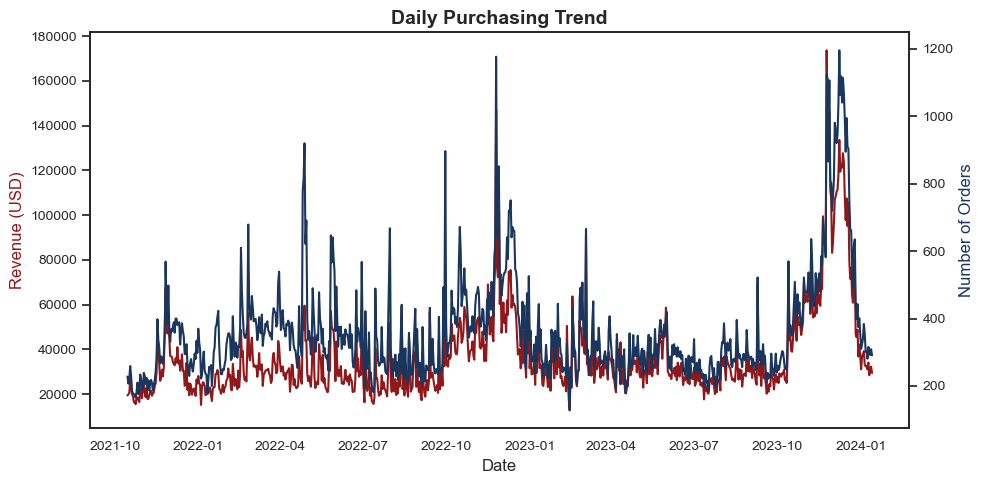

In [10]:
# Display daily revenue and number of orders
plot_purchases(organisation_df)

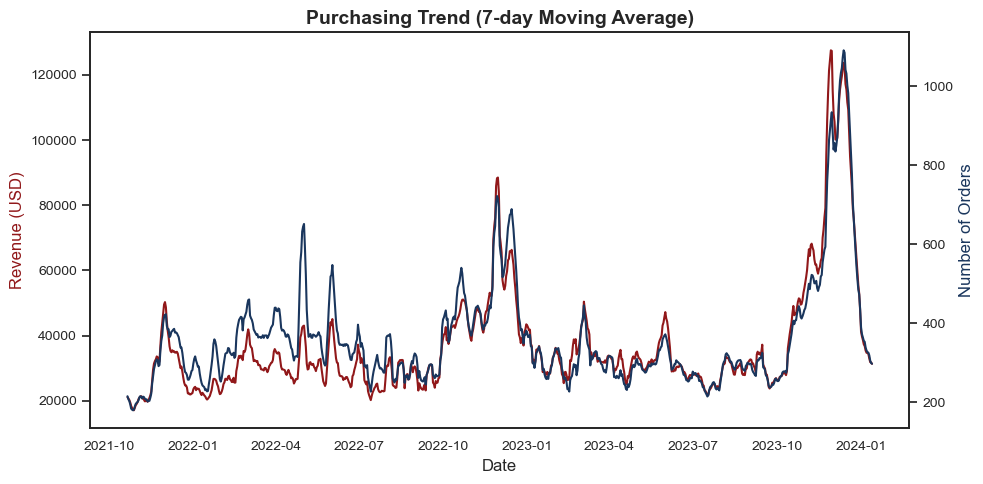

In [11]:
# Display weekly revenue and number of orders
plot_purchases(organisation_df, moving_average=True)

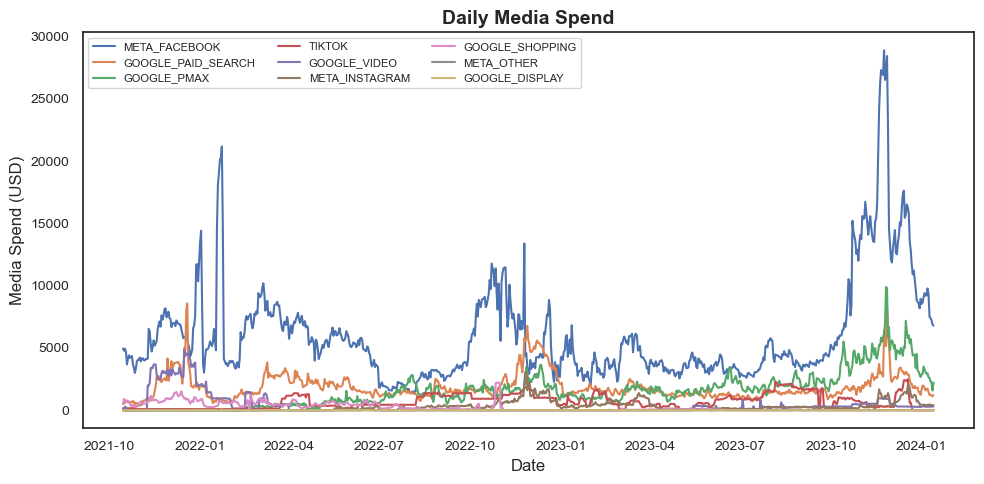

In [12]:
# Display daily media spend
plot_media_spend(organisation_df)

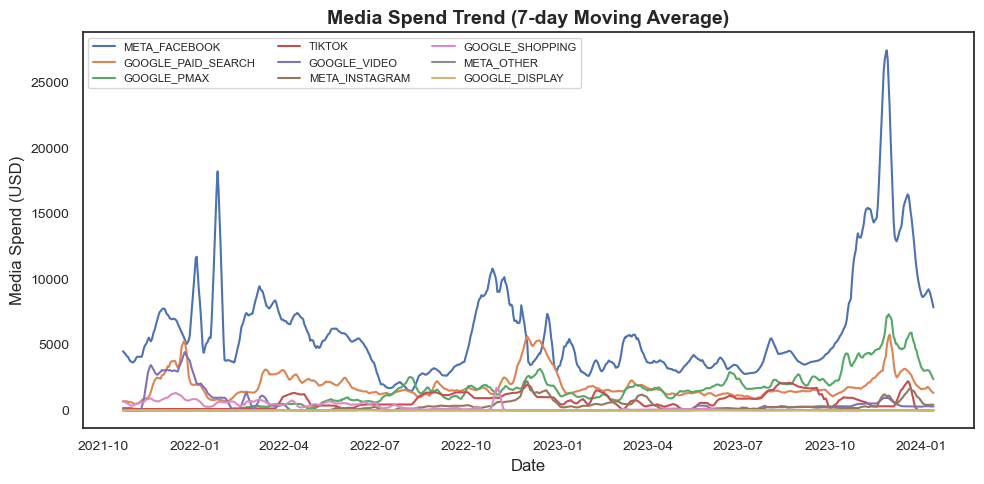

In [13]:
# Display weekly media spend with a rolling average
plot_media_spend(organisation_df, moving_average=True)

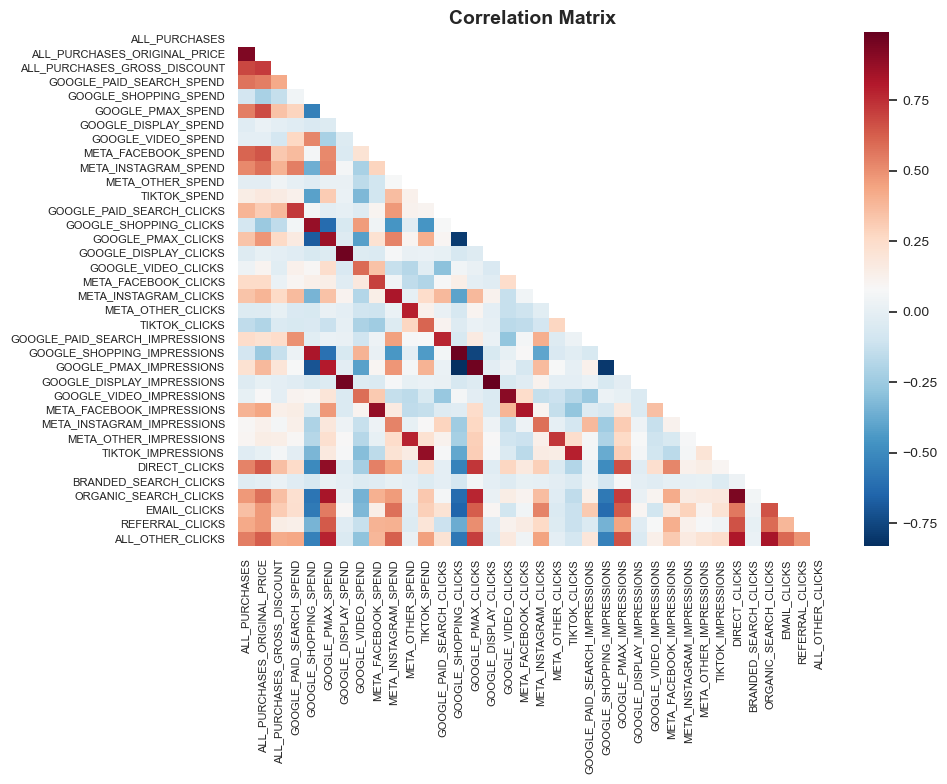

In [14]:
# Display the correlation matrix
plot_correlation(organisation_df)

In [9]:
# Inspect the presence of outliers
outliers_df = inspect_outliers(organisation_df)
outliers_df.style.format(
    {'LOWER_BOUND': '{:,.2f}',
     'Q1': '{:,.2f}',
     'Q2': '{:,.2f}',
     'Q3': '{:,.2f}',
     'UPPER_BOUND': '{:,.2f}',
     'PERCENTAGE_OUTLIERS': '{:,.2f}'})

== OUTLIERS ASSESSMENT ==


,COLUMN,LOWER_BOUND,Q1,Q2,Q3,UPPER_BOUND,NUM_OUTLIERS,PERCENTAGE_OUTLIERS
0,ALL_PURCHASES,128.00,265.00,320.00,397.00,595.00,61,7.43
1,ALL_PURCHASES_ORIGINAL_PRICE,"12,806.05","25,183.20","30,914.44","41,492.86","65,957.34",57,6.94
2,ALL_PURCHASES_GROSS_DISCOUNT,"1,087.39","2,372.61","3,135.07","4,367.43","7,359.65",73,8.89
3,GOOGLE_PAID_SEARCH_SPEND,350.84,"1,284.93","1,557.10","2,136.09","3,412.83",64,7.80
4,GOOGLE_SHOPPING_SPEND,0.00,0.00,66.64,415.34,"1,038.35",21,2.56
5,GOOGLE_PMAX_SPEND,0.00,561.05,"1,378.04","2,012.76","4,190.32",55,6.70
6,GOOGLE_DISPLAY_SPEND,0.00,0.00,0.00,0.00,0.00,9,1.10
7,GOOGLE_VIDEO_SPEND,0.00,0.00,0.00,305.28,763.20,114,13.89
8,META_FACEBOOK_SPEND,"1,367.78","3,478.54","4,638.68","7,045.74","12,396.55",67,8.16
9,META_INSTAGRAM_SPEND,0.00,0.00,175.29,356.22,890.55,76,9.26


---

## **2 - Data Preparation**

In [ ]:
# Prepare the dataset for MMM modelling (organisation_df comes from the previous step)
mmm_df = preprocess_dataset(organisation_df)

== DATASET PREPROCESSING ==

 -> There are 0 missing dates between 2021-10-15 and 2024-01-13

 -> The target variable is ALL_PURCHASES_ORIGINAL_PRICE

 -> The media spend variables are GOOGLE_PAID_SEARCH_SPEND, GOOGLE_SHOPPING_SPEND, GOOGLE_PMAX_SPEND, GOOGLE_VIDEO_SPEND, META_FACEBOOK_SPEND, META_INSTAGRAM_SPEND, TIKTOK_SPEND
 -> The media exposure variables are GOOGLE_PAID_SEARCH_CLICKS, GOOGLE_SHOPPING_CLICKS, GOOGLE_PMAX_CLICKS, GOOGLE_VIDEO_IMPRESSIONS, META_FACEBOOK_IMPRESSIONS, META_INSTAGRAM_IMPRESSIONS, TIKTOK_IMPRESSIONS
 -> The media variables related to GOOGLE_DISPLAY, META_OTHER are excluded as they contribute a share close to 0% of the total spend

 -> The organic media variables used as control are DIRECT_CLICKS, ORGANIC_SEARCH_CLICKS, EMAIL_CLICKS, REFERRAL_CLICKS, ALL_OTHER_CLICKS
 -> The control variable BRANDED_SEARCH_CLICKS is excluded due to the high presence of missing values, which is around 98%

 -> The time variables extracted from DATE_DAY are DAY_OF_WEEK, IS_

---

## **3 - Meridian MMM Model Development**

In [ ]:
# Load the dataset for MMM
mmm_df = load_mmm_dataset('../outputs/tables/mmm_df.csv')

# Configure media channels, controls, and target for MMM
input_data, holdout_id = define_input_data(mmm_df)

# Define and train the model
mmm = train_mmm_model(input_data, holdout_id)

== MERIDIAN MARKETING MIX MODELLING ==

 -> Performing prior predictive sampling

 -> Performing posterior sampling

 -> Correctly saved the trained model


In [ ]:
# Load the trained model and inspect its convergence
mmm = load_model('../outputs/models/trained_mmm.binpb')
inspect_model_convergence(mmm)

== MODEL CONVERGENCE ASSESSMENT ==


Model Quality Checks
Overall Status: PASS
Summary: Passed: No major quality issues were identified.
Health Score: 100.0

Check Results:
----------------------------------------
Convergence Check:
  Status: PASS
  Recommendation: The model has likely converged, as all parameters have R-hat values < 1.2.
----------------------------------------
Baseline Check:
  Status: PASS
  Recommendation: The posterior probability that the baseline is negative is 0.00. We recommend visually inspecting the baseline time series in the Model Fit charts to confirm this.
----------------------------------------
BayesianPPP Check:
  Status: PASS
  Recommendation: The Bayesian posterior predictive p-value is 0.74. The observed total outcome is consistent with the model's posterior predictive distribution.
----------------------------------------
GoodnessOfFit Check:
  Status: PASS
  Recommendation: R-squared = 0.9416 (All), 0.9501 (Train), 0.9131 (Test); MAPE = 0.1116 (All), 0.1061 (Train), 0.1282 (Test); w

In [4]:
# Inspect the quality of the model
plot_model_quality(mmm)

== MODEL QUALITY ASSESSMENT ==



alt.LayerChart(...)

,metric,geo_granularity,evaluation_set,value
0,R_Squared,national,Train,0.9501
1,R_Squared,national,Test,0.9131
2,R_Squared,national,All Data,0.9416
3,MAPE,national,Train,0.1061
4,MAPE,national,Test,0.1282
5,MAPE,national,All Data,0.1116
6,wMAPE,national,Train,0.0933
7,wMAPE,national,Test,0.1167
8,wMAPE,national,All Data,0.0991


alt.LayerChart(...)

In [4]:
# Display adstock effects
plot_adstock_effects(mmm)

== ADSTOCK EFFECTS ANALYSIS ==



alt.FacetChart(...)

In [5]:
# Display hill effects
plot_hill_effects(mmm)

== HILL EFFECTS ANALYSIS ==



alt.FacetChart(...)

alt.FacetChart(...)

In [6]:
# Display the contribution of each channel
plot_channel_contribution(mmm)

== CHANNEL CONTRIBUTION ANALYSIS ==



alt.Chart(...)

alt.LayerChart(...)

alt.FacetChart(...)

---

## **4 - ROI and Marginal ROI Analysis with Credible Intervals**

In [10]:
# Load the trained MMM model and create an instance of the class Analyzer
mmm = load_model('../outputs/models/trained_mmm.binpb')
analyzer_instance = create_analyzer(mmm)

In [11]:
# Estimate incremental contribution of each channel
incremental_contribution_df = compute_incremental_contribution(analyzer_instance)
incremental_contribution_df.style.format(
    {'incremental_outcome': '{:,.2f}',
     'contribution_percentage': '{:.2f}',
     'cumulative_percentage': '{:.2f}'})

== CHANNEL CONTRIBUTION ANALYSIS ==


,channel,incremental_outcome,contribution_percentage,cumulative_percentage
0,GOOGLE_PAID_SEARCH,"2,767,801.50",23.72,23.72
1,GOOGLE_SHOPPING,"331,778.78",2.84,26.56
2,GOOGLE_PMAX,"2,033,691.50",17.43,43.99
3,GOOGLE_VIDEO,"325,342.50",2.79,46.78
4,META_FACEBOOK,"5,163,265.00",44.25,91.03
5,META_INSTAGRAM,"319,298.06",2.74,93.77
6,TIKTOK,"726,789.81",6.23,100.00
7,All Channels,"11,667,959.00",100.00,100.00


In [5]:
# Compute ROI per each channel together with credible intervals
roi_df = compute_roi(analyzer_instance)

== ROI TABLE ==


,channel,roi_mean,roi_median,roi_ci_lo,roi_ci_hi
0,GOOGLE_PAID_SEARCH,1.7982,1.7194,1.0572,2.7996
1,GOOGLE_SHOPPING,1.7187,1.6416,0.9873,2.6928
2,GOOGLE_PMAX,1.5920,1.5349,0.9374,2.4443
3,GOOGLE_VIDEO,1.0437,0.9427,0.4093,2.0273
4,META_FACEBOOK,1.0509,0.9995,0.5966,1.6886
5,META_INSTAGRAM,1.3067,1.2098,0.6367,2.2846
6,TIKTOK,1.2866,1.1611,0.5193,2.5196
7,All Channels,1.2901,1.2680,0.9817,1.6858


In [6]:
# Compute mROI per each channel together with credible intervals
mroi_df = compute_mroi(analyzer_instance)

== MARGINAL ROI TABLE ==


,channel,mroi_mean,mroi_median,mroi_ci_lo,mroi_ci_hi
0,GOOGLE_PAID_SEARCH,0.8960,0.8538,0.3561,1.5666
1,GOOGLE_SHOPPING,0.7612,0.7177,0.3324,1.3228
2,GOOGLE_PMAX,0.8345,0.7990,0.3572,1.4254
3,GOOGLE_VIDEO,0.4219,0.3679,0.1331,0.8827
4,META_FACEBOOK,0.4334,0.4293,0.2027,0.6752
5,META_INSTAGRAM,0.4686,0.4301,0.1706,0.8923
6,TIKTOK,0.5591,0.4921,0.1738,1.1652
7,All Channels,NaN,NaN,NaN,NaN


In [7]:
# Compute the posterior probability that a channel ROI is > 1
roi_probability_df = compute_roi_probability(mmm)
roi_probability_df

== POSTERIOR PROBABILITY (ROI > 1) TABLE ==


,media_channel,P(ROI > 1)
0,GOOGLE_PAID_SEARCH,0.9665
1,GOOGLE_SHOPPING,0.9454
2,GOOGLE_PMAX,0.9196
3,GOOGLE_VIDEO,0.4525
4,META_FACEBOOK,0.4998
5,META_INSTAGRAM,0.6894
6,TIKTOK,0.6213


In [8]:
# Plot response curves with credible intervals
plot_response_curves(mmm)

== RESPONSE CURVES ANALYSIS ==



alt.FacetChart(...)

---

## **5 - SHAP Explainability**

In [3]:
# Load the MMM dataset and the trained model
mmm_df = load_mmm_dataset('../outputs/tables/mmm_df.csv')
mmm = load_model('../outputs/models/trained_mmm.binpb')

# Perform the dataset split for the ML model
X, X_train, X_test, y_train, y_test = build_train_test_sets(mmm_df, mmm)

# Train and evaluate a surrogate ML model to mimic the behaviour of the MMM
trained_model = train_ml_model(X_train, y_train)
evaluate_ml_model(trained_model, X_test, y_test)

== MODEL TRAINING ==
 -> Successfully trained a surrogate HistGradientBoostingRegressor model

== MODEL EVALUATION ==
 -> R2 score: 0.8242


In [4]:
# Extract SHAP values from the trained model using the overall dataset
shap_values = compute_shap_values(trained_model, X)

== SHAP ANALYSIS ==
 -> Successfully computed SHAP values from a Tree Explainer


== SHAP SUMMARY PLOT ==


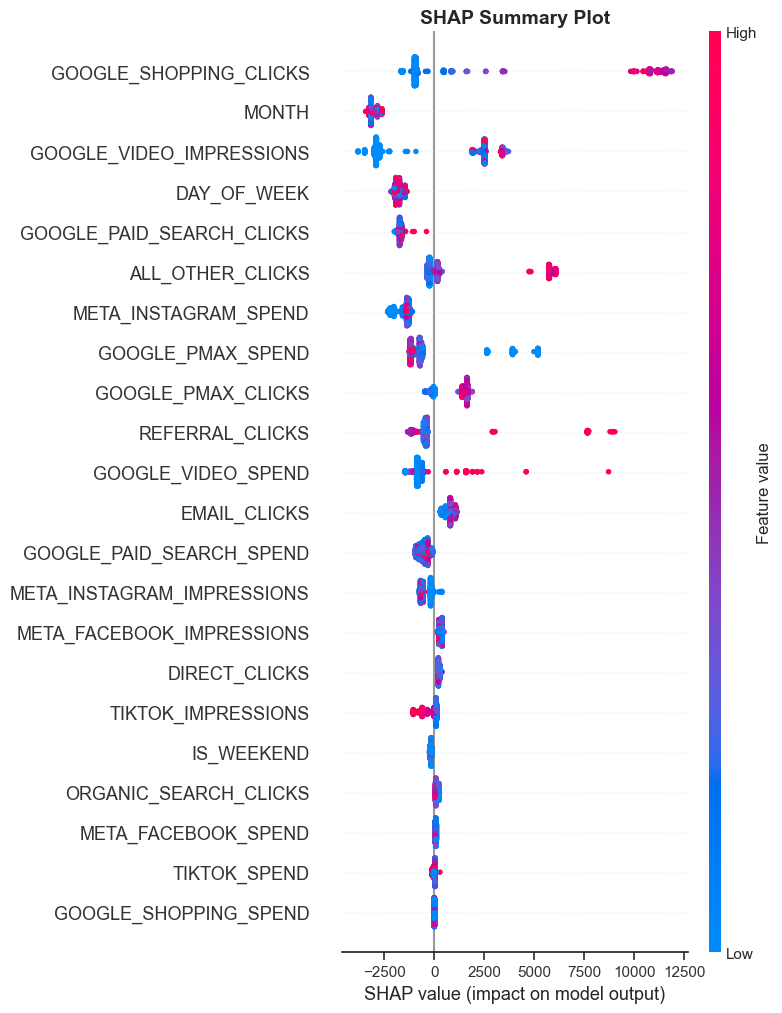

In [5]:
# Display the SHAP summary plot
plot_summary(shap_values, X)

== SHAP DEPENDENCE PLOT ==


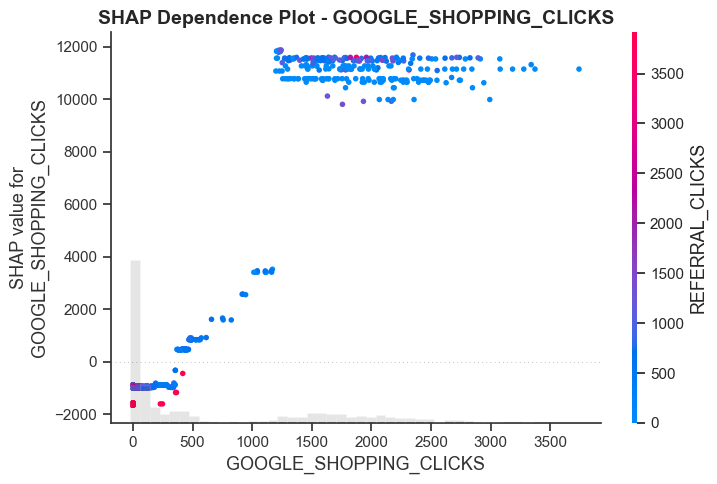

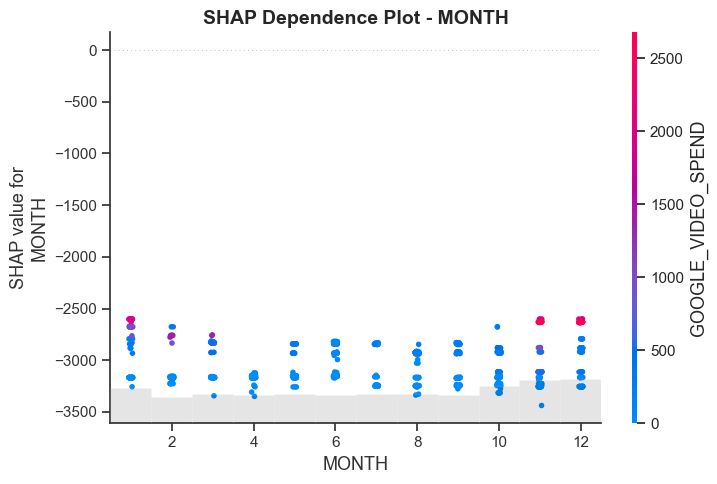

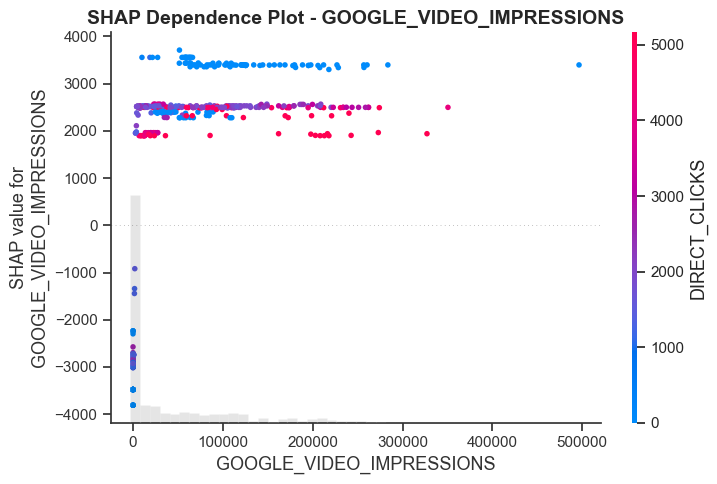

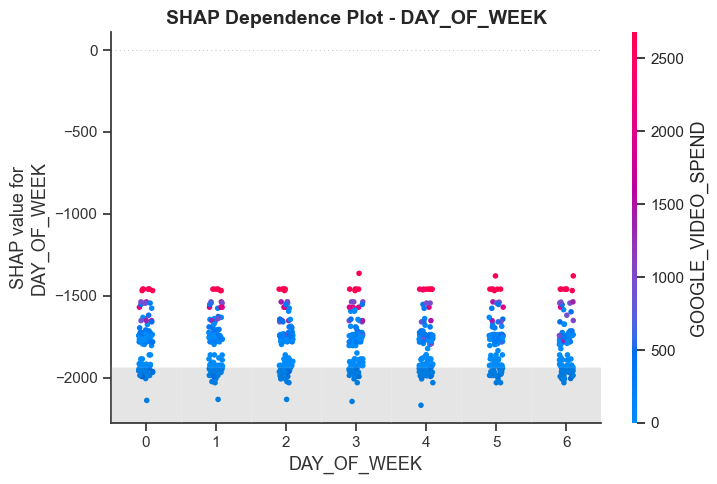

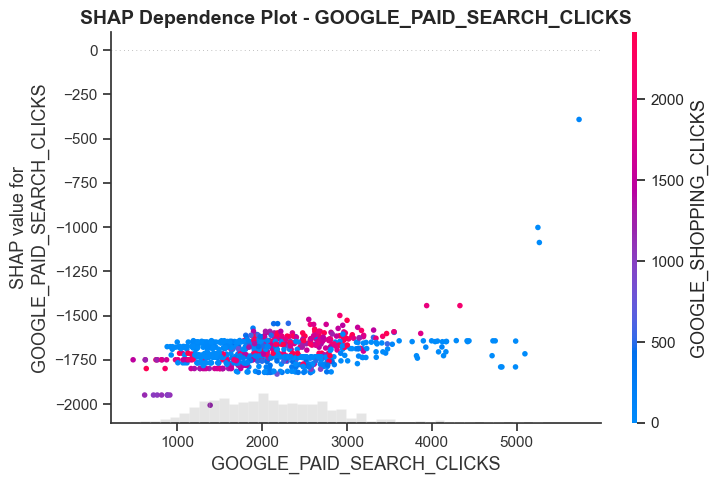

In [6]:
# Display the SHAP dependence plots for the top-5 features
plot_dependence(shap_values, X)

== SHAP FEATURE IMPORTANCE RANKING ==


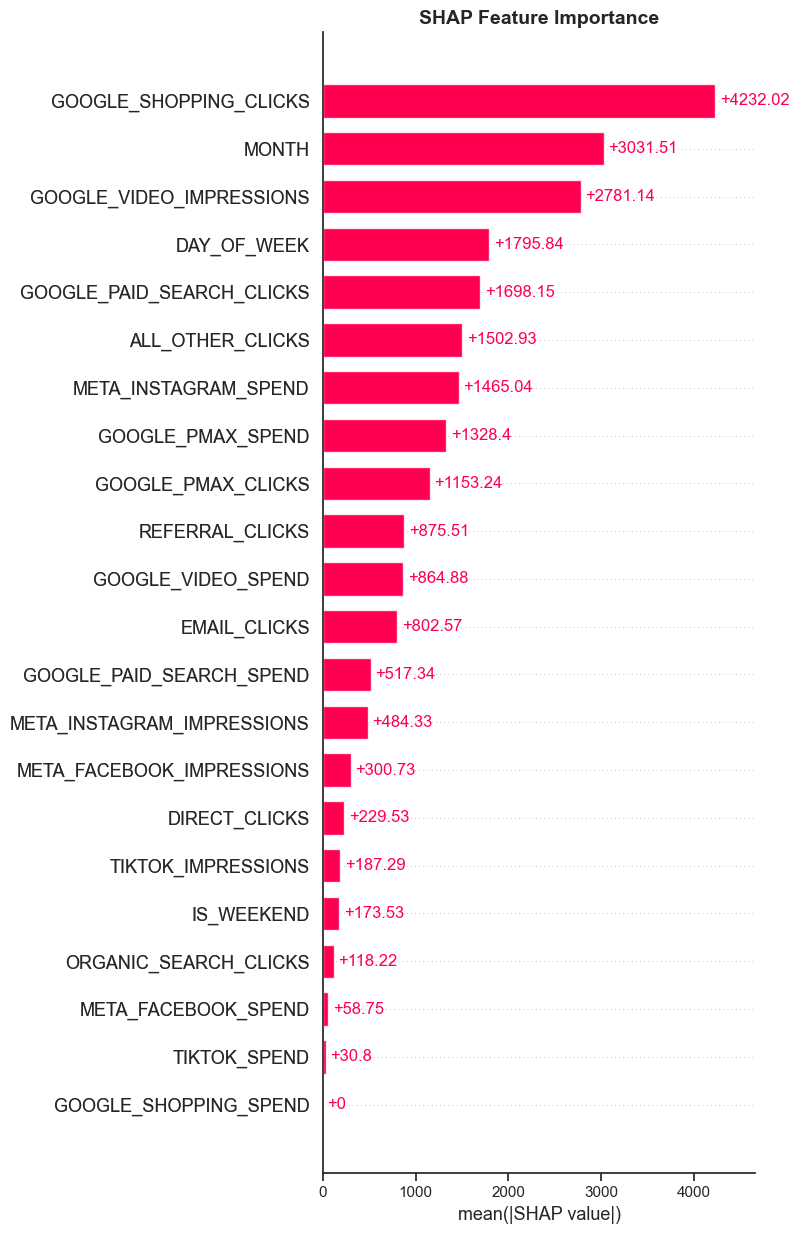

In [7]:
# Display the overall feature importance ranking
plot_feature_importance(shap_values, X)

In [8]:
# Compare SHAP feature importance with MMM media contribution
comparison_df = (
    compare_shap_importance_with_mmm_contribution(shap_values, mmm, X))
comparison_df.style.format(
    {'SHAP_IMPORTANCE': '{:,.2f}',
     'IMPORTANCE_PERCENTAGE': '{:.2f}',
     'MMM_CONTRIBUTION': '{:,.2f}',
     'CONTRIBUTION_PERCENTAGE': '{:.2f}'})

== COMPARISON BETWEEN SHAP IMPORTANCE AND MMM CONTRIBUTION ==


,CHANNEL,SHAP_IMPORTANCE,IMPORTANCE_PERCENTAGE,MMM_CONTRIBUTION,CONTRIBUTION_PERCENTAGE
0,GOOGLE_PAID_SEARCH,"2,215.49",14.67,"2,767,801.50",23.72
1,GOOGLE_SHOPPING,"4,232.02",28.02,"331,778.78",2.84
2,GOOGLE_PMAX,"2,481.65",16.43,"2,033,691.50",17.43
3,GOOGLE_VIDEO,"3,646.02",24.14,"325,342.50",2.79
4,META_FACEBOOK,359.48,2.38,"5,163,265.00",44.25
5,META_INSTAGRAM,"1,949.38",12.91,"319,298.06",2.74
6,TIKTOK,218.09,1.44,"726,789.81",6.23


---

## **6 - Marketing Investment Scenario Simulation with Optimization Techniques**

In [4]:
# Obtain the current level of spend for each channel and the overall amount
mmm = load_model('../outputs/models/trained_mmm.binpb')
media_channels, media_spend, total_spend = compute_current_spend_levels(mmm)

# Extract ROI and mROI for each channel
roi_df = pd.read_csv('../outputs/tables/roi_df.csv')
mroi_df = pd.read_csv('../outputs/tables/mroi_df.csv')
metrics_df = extract_channel_metrics(roi_df, mroi_df)

# Define the most performing channel according to mean ROI
most_performing_channel = get_most_performing_channel(metrics_df)
print(f' -> Most performing channel: {most_performing_channel}')

# Define the list of saturated channels
saturated_channels = get_saturated_channels(metrics_df)
print(f" -> Saturated channels: {', '.join(saturated_channels)}")

== SCENARIO SIMULATION GENERAL SETTING ==
 -> Media channels: GOOGLE_PAID_SEARCH, GOOGLE_SHOPPING, GOOGLE_PMAX, GOOGLE_VIDEO, META_FACEBOOK, META_INSTAGRAM, TIKTOK
 -> Total spend across channels: 9,043,958.13
 -> Most performing channel: GOOGLE_PAID_SEARCH
 -> Saturated channels: GOOGLE_VIDEO, META_FACEBOOK, META_INSTAGRAM


In [5]:
# Perform four optimization scenarios and compare their results
print('== MARKETING INVESTMENT SCENARIO SIMULATION ==')
scenarios_results = []
scenarios_results.extend(optimize_scenario_1(
    mmm, media_channels, media_spend, total_spend, metrics_df))
scenarios_results.extend(optimize_scenario_2(
    mmm, media_channels, media_spend, total_spend, metrics_df))
scenarios_results.extend(optimize_scenario_3(
    mmm, media_channels, media_spend, total_spend, metrics_df))
scenarios_results.extend(optimize_scenario_4(
    mmm, media_channels, media_spend, total_spend, metrics_df))

scenarios_comparison_df = compare_scenarios(scenarios_results)
scenarios_comparison_df.style.format({
    'Budget': '{:,.2f}',
    'Incremental Revenue': '{:,.2f}',
    'Uplift': '{:,.2f}',
    'ROI': '{:.4f}',
})

== MARKETING INVESTMENT SCENARIO SIMULATION ==
 -> Scenario 1 (+20% total) - Equal Allocation
 -> Scenario 1 (+20% total) - mROI Allocation
 -> Scenario 1 (+20% total) - Saturated Channels Allocation
 -> Scenario 2 (+50% most performing channel) - Equal Allocation
 -> Scenario 2 (+50% most performing channel) - mROI Allocation
 -> Scenario 2 (+50% most performing channel) - Saturated Channels Allocation
 -> Scenario 3 (-30% saturated channels) - Equal Allocation
 -> Scenario 3 (-30% saturated channels) - mROI Allocation
 -> Scenario 3 (-30% saturated channels) - Saturated Channels Allocation
 -> Scenario 4 (+10% randomly on half channels) - Equal Allocation
 -> Scenario 4 (+10% randomly on half channels) - mROI Allocation
 -> Scenario 4 (+10% randomly on half channels) - Saturated Channels Allocation

== SCENARIOS COMPARISON ==


,Scenario,Budget,Incremental Revenue,Uplift,ROI
0,Scenario 1 - Equal Allocation,"10,852,749.75","11,577,234.00","1,038,910.00",1.0670
1,Scenario 1 - mROI Allocation,"10,852,749.75","11,545,538.00","858,234.00",1.0631
2,Scenario 1 - Saturated Channels Allocation,"10,852,749.75","12,945,485.00","85,873.00",1.1931
3,Scenario 2 - Equal Allocation,"9,813,571.81","11,063,965.00","1,007,880.00",1.1274
4,Scenario 2 - mROI Allocation,"9,813,571.81","11,058,465.00","842,233.00",1.1269
5,Scenario 2 - Saturated Channels Allocation,"9,813,571.81","12,409,667.00","88,557.00",1.2646
6,Scenario 3 - Equal Allocation,"7,403,156.73","9,677,276.00","926,992.00",1.3067
7,Scenario 3 - mROI Allocation,"7,403,156.73","9,728,026.00","779,867.00",1.3142
8,Scenario 3 - Saturated Channels Allocation,"7,403,156.73","10,910,977.00","93,650.00",1.4741
9,Scenario 4 - Equal Allocation,"9,708,510.59","11,009,082.00","1,004,239.00",1.1339
